# The Christmas order: five Decembers cannot pick the forecaster

**A souvenir shop orders its Christmas stock at the end of September, and its history holds five Decembers to test a forecaster on. A straight line through its sales forecast the last two of them at half of what came. Fitted to the logarithm of sales, which takes one argument, the same forecaster is level with the best. Two forecasters are then off by factors of 1.23 and 1.25, and five Decembers cannot separate them. Generated shops with a known kind of growth show what five Decembers can tell, what each choice costs, and how much to order on top of the forecast.**

A small business rarely has enough history for a backtest to settle anything. This shop has seven years of monthly sales, and the month that decides its year comes once in each. The notebook first does what can be done with the real Decembers. Then it puts the question the real data cannot answer to series made to resemble the shop, where the kind of growth is known because we chose it.

*Data: monthly sales of a souvenir shop on the wharf of a beach resort town in Queensland, Australia, January 1987 to December 1993, from the R package fpp3 ([source and license](data/README.md#souvenir-sales)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import Pipeline, Scenario, cases_from_series
from timegym.statistics import paired_t_interval
from timegym.target import LogTransform

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The shop and the order

The shop's sales grew by about 30% a year, and unevenly: 3% in 1990 and 63% in 1992. December alone brings in a quarter to a third of the year.

The order for Christmas stock goes out at the end of September. So the forecast that matters is the one for December, made with sales known through September, three months ahead. The first two years are needed as history, which leaves five Decembers to test on, 1989 to 1993.

The picture shows the sales twice. On the left in units, where growth is a curve and every December stands taller than the last. On the right on a scale where each step up doubles the sales, where the same growth is close to a straight line and the Decembers stand about as far above it every year.

84 months, January 1987 to December 1993
Growth of the year's sales (%): 1988 +45, 1989 +30, 1990 +3, 1991 +31, 1992 +63, 1993 +35
December's share of the year: 24% to 31%


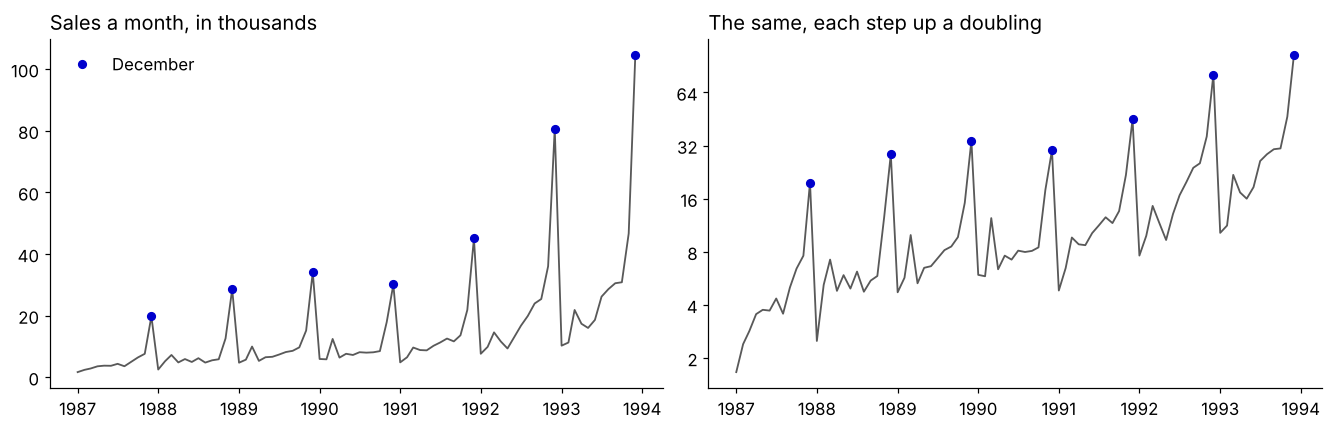

In [2]:
sales = load("souvenir-sales")
sales.index = sales.index.to_timestamp()                  # the first day of each month

by_year = sales["sales"].groupby(sales.index.year).sum()
growth = by_year.pct_change().dropna() * 100
december = sales["sales"][sales.index.month == 12]
share = december.to_numpy() / by_year.to_numpy() * 100

print(f"{len(sales)} months, {sales.index[0]:%B %Y} to {sales.index[-1]:%B %Y}")
print("Growth of the year's sales (%):",
      ", ".join(f"{year} {value:+.0f}" for year, value in growth.items()))
print(f"December's share of the year: {share.min():.0f}% to {share.max():.0f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, title in zip(axes, ["Sales a month, in thousands", "The same, each step up a doubling"]):
    ax.plot(sales.index, sales["sales"] / 1000, color="0.35", linewidth=1.2)
    ax.plot(december.index, december / 1000, "o", color="#0000CC", markersize=5, label="December")
    ax.set_title(title)
axes[1].set_yscale("log", base=2)
axes[1].set_yticks([2, 4, 8, 16, 32, 64], labels=["2", "4", "8", "16", "32", "64"])
axes[0].legend(loc="upper left")
plt.show()

assert len(sales) == 84 and sales.index.freqstr == "MS"
assert round(growth.min()) == 3 and round(growth.max()) == 63
assert 23 < share.min() and share.max() < 33

## Three forecasters, in units and in logarithms

Each forecaster is a small class with `fit` and `predict`. All three treat every calendar month on its own.

- **Last year.** December will be what last December was.
- **Plus growth.** Last December, plus the change from the year before to the last twelve months.
- **Line.** A straight line through all the history, with a level of its own for each calendar month.

Sales that grow by a share each year add more units every year, so a forecaster that adds a fixed number of units falls behind. In logarithms the same growth adds the same amount every year, and "plus growth" and the line fit. `target_transform=LogTransform()` makes the switch: the pipeline hands the forecaster the logarithm of the history and turns its forecast back into units. The forecaster's code stays as it is.

The table gives each December forecast as a share of what came. The score is how far off it was, as a factor: a forecast of 80 and a forecast of 125 for sales of 100 are both off by a factor of 1.25. The last column is the typical factor over the five Decembers.

,1989,1990,1991,1992,1993,Off by a factor of
Share of actual,,,,,,
Last year,0.84,1.13,0.67,0.56,0.77,1.36
"Plus growth, in units",0.91,1.18,0.69,0.63,0.86,1.28
"Plus growth, in logs",1.12,1.31,0.76,0.81,1.16,1.23
"Line, in units",0.80,1.03,0.71,0.47,0.48,1.51
"Line, in logs",1.19,1.55,1.10,0.78,0.86,1.25


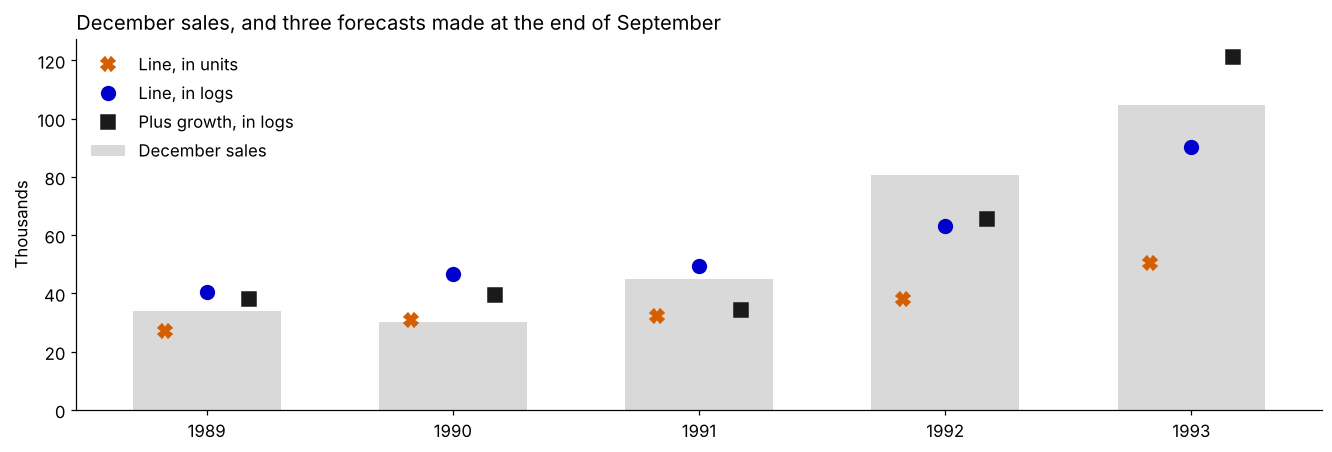

In [3]:
class LastYear:
    def fit(self, history):
        self.values_ = np.asarray(history, dtype=float).ravel()
        return self

    def predict(self, dates):
        return np.resize(self.values_[-12:], len(dates))


class PlusGrowth(LastYear):
    def predict(self, dates):
        values = self.values_
        growth = values[-12:].mean() - values[-24:-12].mean()       # change in a year
        years_ahead = np.arange(len(dates)) // 12 + 1
        return np.resize(values[-12:], len(dates)) + growth * years_ahead


class Line:
    @staticmethod
    def columns(first, count):
        step = first + np.arange(count)
        months = np.zeros((count, 12))
        months[np.arange(count), step % 12] = 1                     # a level per calendar month
        return np.column_stack([step, months])

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.length_ = len(values)
        self.weights_ = np.linalg.lstsq(self.columns(0, len(values)), values, rcond=None)[0]
        return self

    def predict(self, dates):
        return self.columns(self.length_, len(dates)) @ self.weights_


forecasters = {"Last year": LastYear, "Plus growth": PlusGrowth, "Line": Line}

LEAD = 3                                # months from the order to December
origins = [33, 45, 57, 69, 81]          # months of history at the end of each September
cases = cases_from_series(sales, origins, horizon=LEAD, name="sales")
years = [int(case.manifest["origin"][:4]) for case in cases]
assert years == [1989, 1990, 1991, 1992, 1993]
assert all(case.manifest["origin"][5:7] == "09" for case in cases)


def december_gaps(model, cases, transform=None, in_logs=False):
    # The logarithm of forecast over actual, for the last month of every case.
    run = Pipeline(model, target_transform=transform).run(cases=cases, keep_data=True)
    assert run.report.summary["status_counts"]["ERROR"] == 0
    forecast = np.array([entry.forecast.point[-1, 0] for entry in run.cases])
    actual = np.array([np.asarray(entry.case.observed)[-1, 0] for entry in run.cases])
    return forecast - actual if in_logs else np.log(forecast / actual)


def factor(gaps):
    # The typical factor between forecast and actual, whichever of the two is larger.
    return float(np.exp(np.abs(gaps).mean()))


units = {name: december_gaps(model(), cases) for name, model in forecasters.items()}
logs = {name: december_gaps(model(), cases, LogTransform()) for name, model in forecasters.items()}
assert np.allclose(units["Last year"], logs["Last year"])           # nothing to transform

rows = {"Last year": logs["Last year"],
        "Plus growth, in units": units["Plus growth"], "Plus growth, in logs": logs["Plus growth"],
        "Line, in units": units["Line"], "Line, in logs": logs["Line"]}
table = pd.DataFrame({name: np.exp(gaps) for name, gaps in rows.items()}, index=years).T.round(2)
table["Off by a factor of"] = [round(factor(gaps), 2) for gaps in rows.values()]
display(table.rename_axis("Share of actual"))

actual = december[december.index.year >= 1989].to_numpy() / 1000
marks = [("Line, in units", "X", "#D55E00"), ("Line, in logs", "o", "#0000CC"),
         ("Plus growth, in logs", "s", "0.1")]
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.bar(years, actual, width=0.6, color="0.85", label="December sales")
for (name, marker, color), shift in zip(marks, [-0.17, 0.0, 0.17]):
    ax.plot(np.array(years) + shift, actual * np.exp(rows[name]), marker, color=color,
            markersize=9, linestyle="none", label=name)
ax.set_title("December sales, and three forecasts made at the end of September")
ax.set_ylabel("Thousands")
ax.set_xticks(years)
ax.legend(loc="upper left")
plt.show()

typical = table["Off by a factor of"]
assert typical["Last year"] == 1.36
assert typical["Plus growth, in units"] == 1.28 and typical["Plus growth, in logs"] == 1.23
assert typical["Line, in units"] == 1.51 and typical["Line, in logs"] == 1.25
assert (table.loc["Line, in units", [1992, 1993]] < 0.5).all()
assert (table.loc["Last year"] < 1).sum() == 4 and table.loc["Last year", 1990] > 1

In units the line is the worst of the lot. It forecast the Decembers of 1992 and 1993 at 47% and 48% of what came. In logarithms the same class is off by a factor of 1.25, level with "plus growth" at 1.23. "Last year" is too low in four Decembers of five, which is what leaving growth out does. The one December it overshot is 1990, when sales fell.

## Five Decembers

So two forecasters are left, and one is ahead by a hair. Is that lead worth anything? The usual tool is an interval for the difference, from the five pairs of misses.

In [4]:
def against(first, second):
    more = paired_t_interval(np.abs(logs[first]) - np.abs(logs[second]))
    low, high = np.exp(more["ci95"])
    print(f"{first} against {second}: its miss is {np.exp(more['mean']):.2f} times "
          f"as large ({low:.2f} to {high:.2f})")
    return low, high


tie = against("Plus growth", "Line")
blind = against("Last year", "Line")
assert tie[0] < 0.9 and tie[1] > 1.1
assert blind[0] < 1 < blind[1]

Plus growth against Line: its miss is 0.98 times as large (0.84 to 1.15)
Last year against Line: its miss is 1.09 times as large (0.78 to 1.52)


The interval for the two runs from a miss 16% smaller to one 15% larger. It cannot even tell "last year" from the line, though "last year" was too low four times in five. Five numbers are too few for an interval to say much.

## Shops with a known answer

What would this backtest say if we knew which forecaster was right? `Scenario` generates series from a recipe, so we can make shops like this one and choose how their growth behaves. In logarithms, where the forecasters work, a generated shop is a straight line with the shop's growth, a yearly cycle, and surprises. The surprises come in two kinds.

- **Surprises fade.** A good month says nothing about the next one, and sales come back to the line. The line is the right forecaster here.
- **Surprises stay.** A good month lifts every month after it, and sales wander away from any line drawn through the past. Last year's level plus the recent growth is the better guide here.

Three numbers are measured on the shop: its growth per month, how far its sales sit from its line (the size of the surprises that fade), and how much its change from one year to the next varies (the size of the surprises that stay). The yearly cycle of a generated shop is a smooth wave and not a December peak. That makes no difference to forecasters that treat every calendar month on its own, and the code checks it.

For each kind we generate 500 shops of 84 months and run the same five-December backtest on every one of them. The generated series are already logarithms, so the forecasters run on them as they are.

Growth a month 2.3%, surprises that fade 0.186, surprises that stay 0.064 a month


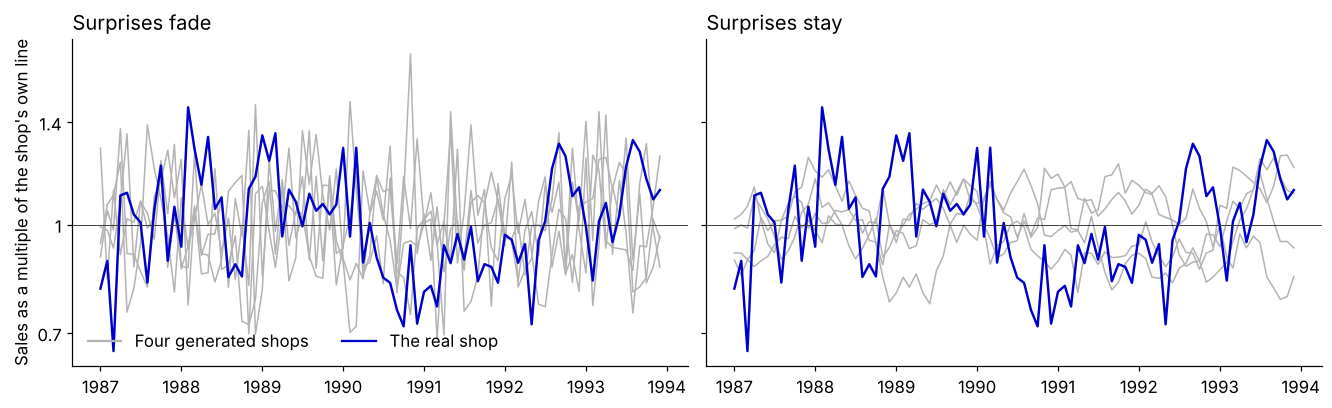

Share of a month's distance from the line still there a month later
  the real shop: 0.51
  surprises fade: -0.20 to 0.18 in nine shops of ten
  surprises stay: 0.78 to 0.97 in nine shops of ten


In [5]:
log_sales = np.log(sales["sales"].to_numpy())
SHOPS = 500
KINDS = {"Surprises fade": "white_noise", "Surprises stay": "random_walk"}


def around_line(values):
    # A series less the line fitted through it.
    return values - Line.columns(0, len(values)) @ Line().fit(values).weights_


def carried(values):
    # The share of a month's distance from the line that is still there a month later.
    distance = around_line(values)
    return float(np.corrcoef(distance[1:], distance[:-1])[0, 1])


growth_a_month = float(Line().fit(log_sales).weights_[0])
fade_size = float(around_line(log_sales).std(ddof=13))                       # 13 fitted weights
stay_size = float((log_sales[12:] - log_sales[:-12]).std(ddof=1) / np.sqrt(12))
print(f"Growth a month {np.expm1(growth_a_month) * 100:.1f}%, "
      f"surprises that fade {fade_size:.3f}, surprises that stay {stay_size:.3f} a month")


def recipe(kind, months, cycle=0.6):
    size = fade_size if kind == "white_noise" else stay_size
    return Scenario("composite", history_length=months, horizon=LEAD,
                    parameters={"intercept": 8.0, "slope": growth_a_month, "amplitude": cycle,
                                "period": 12.0, "residual": kind, "sigma": size})


def generated(kind, shops=SHOPS, cycle=0.6):
    # Shops of 84 months, and the five-December backtest cut from each.
    cases, series = [], []
    scenario = recipe(kind, 81, cycle)
    for seed in range(shops):
        made = Scenario(scenario.kind, history_length=81, horizon=LEAD,
                        parameters=scenario.parameters, seed=seed).generate()
        months = pd.concat([made.task.history, made.observed])
        series.append(months["y"].to_numpy())
        cases += cases_from_series(months, origins, horizon=LEAD, name=f"shop-{seed}")
    return cases, np.array(series)


# The shape of the year does not matter here: the same shops with no cycle give the same gaps.
wave, _ = generated("random_walk", shops=20)
flat, _ = generated("random_walk", shops=20, cycle=0.0)
for model in forecasters.values():
    assert np.allclose(december_gaps(model(), wave, in_logs=True),
                       december_gaps(model(), flat, in_logs=True), atol=1e-8)

backtests, spread, examples = {}, {}, {}
for label, kind in KINDS.items():
    shop_cases, series = generated(kind)
    examples[label] = series[:4]
    spread[label] = np.quantile([carried(values) for values in series], [0.05, 0.95])
    backtests[label] = {name: december_gaps(model(), shop_cases, in_logs=True).reshape(SHOPS, 5)
                        for name, model in forecasters.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained", sharey=True)
for ax, (label, series) in zip(axes, examples.items()):
    for values in series:
        ax.plot(sales.index, np.exp(around_line(values)), color="0.7", linewidth=1)
    ax.plot(sales.index, np.exp(around_line(log_sales)), color="#0000CC", linewidth=1.6)
    ax.axhline(1, color="0.2", linewidth=0.6)
    ax.set_yscale("log")
    ax.set_yticks([0.5, 0.7, 1, 1.4, 2], labels=["0.5", "0.7", "1", "1.4", "2"])
    ax.minorticks_off()
    ax.set_title(label)
axes[0].plot([], [], color="0.7", label="Four generated shops")
axes[0].plot([], [], color="#0000CC", label="The real shop")
axes[0].legend(loc="lower left", ncols=2)
axes[0].set_ylabel("Sales as a multiple of the shop's own line")
plt.show()

shop_carried = carried(log_sales)
print("Share of a month's distance from the line still there a month later")
print(f"  the real shop: {shop_carried:.2f}")
for label, (low, high) in spread.items():
    print(f"  {label.lower()}: {low:.2f} to {high:.2f} in nine shops of ten")

assert round(np.expm1(growth_a_month) * 100, 1) == 2.3
assert round(fade_size, 3) == 0.186 and round(stay_size, 3) == 0.064
assert spread["Surprises fade"][1] < 0.25 < 0.45 < shop_carried < 0.6 < 0.7 < spread["Surprises stay"][0]

The real shop is neither kind. Half of a month's distance from its line is still there a month later, which is more than in any shop where surprises fade and less than in any where they stay. It has some of each, so the two kinds are the two ends, and the shop sits somewhere between them.

Now the backtest on every generated shop: the typical factor each forecaster is off by, and how often the five Decembers put one forecaster ahead of another.

In [6]:
def miss(gaps):
    return np.abs(gaps).mean(axis=1)                 # one number for each shop's backtest


typical = pd.DataFrame({label: {name: np.exp(miss(gaps).mean()) for name, gaps in found.items()}
                        for label, found in backtests.items()}).T
typical.loc["The real shop"] = {name: factor(gaps) for name, gaps in logs.items()}
display(typical.round(2).rename_axis("Off by a factor of"))

ahead = pd.DataFrame({label: {
    "Plus growth ahead of Line": (miss(found["Plus growth"]) < miss(found["Line"])).mean() * 100,
    "Last year ahead of Line": (miss(found["Last year"]) < miss(found["Line"])).mean() * 100,
} for label, found in backtests.items()}).T
display(ahead.round(0).astype(int).rename_axis("Share of backtests (%)"))

assert typical.loc["Surprises fade"].round(2).tolist() == [1.36, 1.25, 1.19]
assert typical.loc["Surprises stay"].round(2).tolist() == [1.36, 1.20, 1.20]
assert 15 < ahead.loc["Surprises fade", "Plus growth ahead of Line"] < 23
assert 43 < ahead.loc["Surprises stay", "Plus growth ahead of Line"] < 52
assert ahead["Last year ahead of Line"].max() < 12

,Last year,Plus growth,Line
Off by a factor of,,,
Surprises fade,1.36,1.25,1.19
Surprises stay,1.36,1.20,1.20
The real shop,1.36,1.23,1.25


,Plus growth ahead of Line,Last year ahead of Line
Share of backtests (%),,
Surprises fade,19,3
Surprises stay,47,9


Three things can be read off these tables.

**Five Decembers are enough to drop "last year".** It comes out ahead of the line in 3% of backtests where surprises fade and in 9% where they stay. The interval could not say that, and 500 shops with a known answer can.

**They are enough to find the line when the line is right.** Where surprises fade, the line wins four backtests in five.

**They are not enough for the shop's own question.** Where surprises stay, the two forecasters are off by the same factor of 1.20 and the backtest is a coin flip. A backtest that puts "plus growth" ahead, as the shop's did, turns up in about half the shops of that kind and in one in five of the other. The shop's backtest leans toward surprises that stay, and proves nothing.

## What each choice costs

If the backtest cannot choose, the next question is what a wrong choice costs. Here the generated shops have a direct answer: forecast the next December of every shop with each forecaster, once with the shop's seven years of history and once with twelve, and score against what came. A third forecast is added, the **average of the two** in logarithms. It needs no run of its own, since its gap is the average of the two gaps.

The second table is the order itself. No forecast is the order: order the forecast and the shop is short about every other December. The table gives the multiple of the forecast that would have covered nine Decembers in ten.

In [7]:
def next_december(kind, months):
    # Gaps for the December after `months` of history, one for each generated shop.
    gaps = {}
    for name in ["Plus growth", "Line"]:
        run = Pipeline(forecasters[name]()).run(scenarios=[recipe(kind, months)], instances=SHOPS, keep_data=True)
        assert len({entry.case.manifest["seed"] for entry in run.cases}) == SHOPS
        gaps[name] = np.array([entry.forecast.point[-1, 0] - np.asarray(entry.case.observed)[-1, 0]
                               for entry in run.cases])
    gaps["Average of the two"] = (gaps["Plus growth"] + gaps["Line"]) / 2
    return gaps


off, cover, short = {}, {}, {}
for label, kind in KINDS.items():
    for years_known, months in [(7, 81), (12, 141)]:
        column = (label, f"{years_known} years")
        gaps = next_december(kind, months)
        off[column] = {name: factor(found) for name, found in gaps.items()}
        cover[column] = {name: np.exp(-np.quantile(found, 0.1)) for name, found in gaps.items()}
        short[column] = (gaps["Average of the two"] < 0).mean()     # the forecast was too low
off, cover = pd.DataFrame(off), pd.DataFrame(cover)
display(off.round(2).rename_axis("Off by a factor of"))
display(cover.round(2).rename_axis("Order this multiple"))

both = (logs["Plus growth"] + logs["Line"]) / 2
print(f"On the shop's five Decembers the average is off by a factor of {factor(both):.2f}; "
      f"\nthe largest December was {np.exp(-both.min()):.2f} times its forecast.")

best = off.min()
assert (off.loc["Average of the two"] - best).max() < 0.025
fade, stay = "Surprises fade", "Surprises stay"
assert off.loc["Line", (fade, "7 years")] < off.loc["Plus growth", (fade, "7 years")] - 0.05
assert off.loc["Line", (stay, "12 years")] > off.loc["Line", (stay, "7 years")] + 0.05
assert off.loc["Line", (stay, "12 years")] > off.loc["Plus growth", (stay, "12 years")] + 0.05
assert all(0.4 < share < 0.6 for share in short.values())
assert abs(off.loc["Plus growth"].max() - off.loc["Plus growth"].min()) < 0.07
assert 1.2 < cover.loc["Average of the two"].min() and cover.loc["Average of the two"].max() < 1.4
assert round(factor(both), 2) == 1.18

Surprises fade          Surprises stay         
                          7 years 12 years        7 years 12 years
Off by a factor of                                                
Plus growth                  1.25     1.25           1.19     1.21
Line                         1.17     1.18           1.22     1.29
Average of the two           1.19     1.20           1.16     1.19

Surprises fade          Surprises stay         
                           7 years 12 years        7 years 12 years
Order this multiple                                                
Plus growth                   1.44     1.41           1.32     1.38
Line                          1.25     1.29           1.37     1.47
Average of the two            1.33     1.31           1.25     1.30

On the shop's five Decembers the average is off by a factor of 1.18; 
the largest December was 1.25 times its forecast.


No forecaster is best everywhere. The line is best where surprises fade. Where they stay it gets worse with every year of history it is given, because it still leans on where the shop was years ago. "Plus growth" is about the same at any age and pays for that where surprises fade. The average of the two is within a few hundredths of the best in every column. For a shop that sits between the two kinds, it is the choice that cannot go far wrong, and on the shop's five real Decembers it is off by a factor of 1.18, against 1.23 and 1.25 for its two parts.

The order is the forecast times about 1.3, if being short one December in ten is acceptable. What the extra third costs, set against an empty shelf in the best month of the year, is for the shop to weigh. The forecasts alone would not have said that a third is the size of the question.

## What TimeGym added

- **Logarithms with one argument.** `target_transform=LogTransform()` handed each forecaster the logarithm of its history and turned the forecast back into units. The line went from the worst of the lot to level with the best, and its code did not change.
- **The same forecasters on real and generated series.** The three classes that ran on the shop ran as they are on a thousand generated shops, through the same `cases_from_series` and `Pipeline`.
- **Shops with a known kind of growth.** `Scenario` made series from a recipe measured on the shop, with surprises that fade or that stay. That showed what a five-December backtest can tell, which the shop's own data cannot show, and what each choice costs under each kind.
- **Every forecast kept.** The share of backtests each forecaster won, the average of two forecasts and the order multiples were all worked out from the kept forecasts after the runs.

## Change one thing

- Place the order at the end of June: cut the cases three months earlier and set `LEAD = 6`. How much does the order multiple grow?
- Add a forecaster that adds half the growth. Where does it come out under each kind?
- Give the generated shops fifteen years and backtest on thirteen Decembers. How often does the backtest now pick "plus growth" where surprises stay?
- Halve `stay_size`. Does the line still get worse with age?
- Forecast the whole next year with `horizon=12` and score every month. Is December the hardest month, as a factor?

**What this doesn't show.** The two kinds of shop are assumptions, with their sizes measured on 84 months. The real shop sits between them, and nothing here says where. Every generated shop grows at one steady pace; the real one grew 63% in 1992, and a lasting change of pace is in neither kind. The three forecasters are the simplest that fit the job. Someone who knew the town, a new ferry or a festival, would beat all of them in the year it mattered. This is one shop from a textbook exercise, its sales are in a unit the source does not state, and the five Decembers are all there is.

**Related:** [You tried 50 models](best-of-fifty.ipynb) has the opposite problem, 114 series to compare on, where an interval does work. [The forest that cannot follow growth](passenger-growth.ipynb) is another growing monthly series. [Weekly shop sales](store-sales.ipynb) goes from a forecast to a stock order week by week. [Target transforms](../tutorials/04_target_transforms.ipynb) covers `LogTransform` and its relatives. More examples are on the [examples page](../docs/examples.md).